# 02 · Von der Mathematik zu gespeicherten Werten

**NHyDB-0.27.1-Notebook-Reihe · v1**

Notebook 01 hat gezeigt, dass jede Zelle eine Zahl *ist*. Jetzt legen wir echte Daten in diese Zellen: eine Datenbank anlegen, Datensätze schreiben, sehen, **wo** sie im Dynadron liegen, denselben Wert auf drei verschiedenen Wegen lesen, die Datenbank schließen und wieder öffnen.

> **Für wen ist das?** Dieses Notebook beginnt mit einer kurzen Einführung und geht dann in ausführbare Beispiele über. **Neu bei NHyDB?** Lies von oben nach unten – jede Idee wird eingeführt, bevor sie verwendet wird. **Kennst du die Grundlagen schon?** Überspringe die mit 📘 *Hintergrund* markierten Abschnitte und springe zu den mit ▶ markierten Experimenten. Alle Zellen laufen von oben nach unten; optionale Vertiefungen sind mit ⏩ *Vertiefung* markiert.

**Was du lernst**

* wie du eine Datenbank mit einem Realm, einer Shape und einem CLASSIC-Layout anlegst
* wo jeder gespeicherte Wert liegt: seine Zelle `(R, u, v, lane)` und seine Zahl `N`
* drei Wege zum selben Wert: über Koordinaten, über den Datensatz und über `N`
* warum ein riesiger Adressraum **keine** riesige Datei bedeutet

**Vorher empfohlen:** [01 · Die Adresse ist die Identität](01_the_address_is_the_identity_v1.ipynb).

### Einrichtung

Die nächste Zelle prüft die Umgebung und definiert ein paar kleine Zeichenhilfen für dieses
Notebook. Sie ist eingeklappt, weil es darin nicht um NHyDB selbst geht – du kannst sie aber
gern öffnen. Jede Datenbank in diesem Notebook liegt in einem temporären Ordner, der am Ende
gelöscht wird.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def kind_of(n):
    """'NL', 'NR', 'GZ' or 'N0' for a natural number n >= 1 (computed by NHyDB)."""
    try:
        return nhydb.n_to_dynadron_address(n)["lane_name"]
    except nhydb.AddressError:
        return "GZ" if math.isqrt(n) ** 2 == n else "N0"


def group_of(n):
    """The group G whose interval [G(G-1), G(G+1)) contains n."""
    g = math.isqrt(n)
    return g + 1 if n - g * g >= g else g       # N0(g+1) and the NL cells of g+1 lie above g² + g − 1


KIND_LABEL = {"NL": "NL cell", "NR": "NR cell", "GZ": "GZ point (G²)", "N0": "N0 point (G·(G−1))"}


def plot_staircase(ax, g_max=10, highlight=(), annotate=True, title=None, g_min=1):
    """Every natural number 1 … g_max·(g_max+1)−1 in its group row.

    Row G holds the numbers G(G−1) … G(G+1)−1. The horizontal position is N − G²:
    NL cells sit at −u (left of the square G²), NR cells at +v (right of it).
    """
    highlight = set(highlight)
    for g in range(g_min, g_max + 1):
        for n in range(max(1, g * (g - 1)), g * (g + 1)):
            k = kind_of(n)
            x, y = n - g * g, -g
            face = COLORS[k]
            alpha = 1.0 if k in ("GZ", "N0") else 0.85
            ax.add_patch(Rectangle((x - 0.47, y - 0.42), 0.94, 0.84, facecolor=face, alpha=alpha,
                                   edgecolor=COLORS["attention"] if n in highlight else "white",
                                   linewidth=2.6 if n in highlight else 0.5))
            if annotate:
                ax.text(x, y, str(n), ha="center", va="center", color="white",
                        fontsize=7 if n < 100 else 6, fontweight="bold")
    ax.set_xlim(-g_max - 1, g_max)
    ax.set_ylim(-g_max - 0.8, -g_min + 0.8)
    ax.set_yticks([-g for g in range(g_min, g_max + 1)])
    ax.set_yticklabels([f"G={g}" for g in range(g_min, g_max + 1)])
    ax.set_xlabel("position in the group:  N − G²   (NL: −u   ·   GZ: 0   ·   NR: +v)")
    ax.axvline(0, color=COLORS["GZ"], lw=0.8, ls=":", zorder=0)
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    ax.spines["left"].set_visible(False)
    handles = [Rectangle((0, 0), 1, 1, color=COLORS[k]) for k in ("N0", "NL", "GZ", "NR")]
    ax.legend(handles, [KIND_LABEL[k] for k in ("N0", "NL", "GZ", "NR")], ncol=4,
              loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False, fontsize=9)
    if title:
        ax.set_title(title)


def plot_address_grid(ax, u_max, v_max, lane, highlight=(), annotate=True, title=None, values=None):
    """The (u, v) plane of realm 1 for one lane; every square shows its number N.

    Anti-diagonals u + v = G are the groups. ``highlight`` is a set of (u, v);
    ``values`` maps (u, v) to a short text shown under N (stored data).
    """
    import matplotlib.colors as mcolors
    base = COLORS[lane]
    cmap = mcolors.LinearSegmentedColormap.from_list(lane, ["#ffffff", base])
    highlight = set(highlight)
    g_top = u_max + v_max
    for u in range(1, u_max + 1):
        for v in range(1, v_max + 1):
            n = nhydb.dynadron_n(1, u, v, lane)
            g = u + v
            shade = 0.25 + 0.6 * (g - 2) / max(1, g_top - 2)
            ax.add_patch(Rectangle((u - 0.5, v - 0.5), 1, 1, facecolor=cmap(shade),
                                   edgecolor=COLORS["attention"] if (u, v) in highlight else "white",
                                   linewidth=2.6 if (u, v) in highlight else 0.8, zorder=2 if (u, v) in highlight else 1))
            if annotate:
                txt = str(n)
                if values and (u, v) in values:
                    txt += "\n" + str(values[(u, v)])
                ax.text(u, v, txt, ha="center", va="center", fontsize=7.5 if n < 1000 else 6.5,
                        color="white" if shade > 0.55 else "#111827", zorder=3)
    for g in range(2, g_top + 1):        # group diagonals u + v = G
        ax.plot([g - v_max - 0.5, g - 0.5], [v_max + 0.5, 0.5], color="#94a3b8", lw=0.4, zorder=0)
    ax.set_xlim(0.5, u_max + 0.5)
    ax.set_ylim(0.5, v_max + 0.5)
    ax.set_xticks(range(1, u_max + 1))
    ax.set_yticks(range(1, v_max + 1))
    ax.set_xlabel("u")
    ax.set_ylabel("v")
    ax.set_aspect("equal")
    ax.set_title(title or f"lane {lane}:  N = G² {'−' if lane == 'NL' else '+'} {'u' if lane == 'NL' else 'v'}",
                 color=base)


def plot_path(ax, steps, title=None):
    """'From input to value': boxes coloured by layer A/B/C, connected by arrows.

    ``steps`` is a list of (layer, heading, text) with layer in {"A", "B", "C"}.
    """
    n = len(steps)
    width, gap = 1.0, 0.35
    for i, (layer, head, text) in enumerate(steps):
        x = i * (width + gap)
        ax.add_patch(FancyBboxPatch((x, 0), width, 1, boxstyle="round,pad=0.02,rounding_size=0.06",
                                    facecolor=COLORS[layer + "_light"], edgecolor=COLORS[layer], lw=1.6))
        ax.text(x + width / 2, 0.80, head, ha="center", va="center", fontsize=8.5,
                fontweight="bold", color=COLORS[layer])
        ax.text(x + width / 2, 0.40, text, ha="center", va="center", fontsize=8, color="#111827",
                wrap=True)
        if i < n - 1:
            ax.annotate("", xy=(x + width + gap - 0.02, 0.5), xytext=(x + width + 0.02, 0.5),
                        arrowprops=dict(arrowstyle="-|>", color="#334155", lw=1.3))
    ax.set_xlim(-0.1, n * (width + gap) - gap + 0.1)
    ax.set_ylim(-0.35, 1.15)
    ax.axis("off")
    for j, (layer, name) in enumerate([("A", "A · address space"), ("B", "B · data model"),
                                       ("C", "C · storage engine")]):
        ax.text(j * 1.6, -0.25, "■ " + name, color=COLORS[layer], fontsize=8.5, fontweight="bold")
    if title:
        ax.set_title(title)

import pandas as pd

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 Hintergrund: drei kleine Bausteine

| Begriff | Bedeutung | Hier |
|---|---|---|
| **Realm** | ein nummerierter Adressbereich | Realm `1`, Name *library* |
| **Shape** | die typisierten Felder eines Datensatzes (`v = 1 … k`) | *book*: `title`, `author`, `year` |
| **Layout** | wie Datensätze auf Zellen verteilt werden | **CLASSIC**: Datensatz = `u`, Feld = `v` |

In einem CLASSIC-Layout ist Datensatz Nummer 2 die Zeile `u = 2`, und seine Felder sind die Zellen
`v = 1, 2, 3` dieser Zeile. Mehr braucht es nicht – keine Tabelle, keine Schlüsselspalte.

## 1 · Eine Datenbank anlegen und Daten schreiben

**Frage:** Was braucht es, um ein paar Datensätze zu speichern?

▶ **Ausprobieren:** Wir legen die Datenbank an, definieren Realm, Shape und Layout und schreiben auf
drei verschiedene Arten – einen Datensatz, einen Batch von Datensätzen und eine einzelne
zusätzliche Zelle auf der anderen Lane (eine Notiz auf der NR-Lane von Buch 2). Beim Verlassen des
`with`-Blocks wird committet und geschlossen.

In [2]:
PATH = db_path("library.nhydb")

with nhydb.create(PATH) as db:
    db.create_realm(1, "library")
    db.create_shape(1, 1, "book", [
        {"v": 1, "name": "title",  "type": "utf8"},
        {"v": 2, "name": "author", "type": "utf8"},
        {"v": 3, "name": "year",   "type": "u16"},
    ])
    db.create_classic_layout(1, 1, "books", shape_id=1)       # layout 1 in realm 1

    db.put_record(1, 1, {"title": "Flatland", "author": "Abbott", "year": 1884})   # one record
    db.put_dense_batch(1, 2, [                                                       # u = 2, 3, 4
        ["Gödel, Escher, Bach", "Hofstadter", 1979],
        ["The Joy of x", "Strogatz", 2012],
        ["Proofs from THE BOOK", "Aigner & Ziegler", 1998],
    ], shape_id=1)
    db.put_cell(1, 2, 1, "signed copy", type="utf8", lane="NR")                     # one cell

print("files:", file_sizes(PATH))

files: {'library.nhydb': 9408, 'library.nhydb.layout.enc': 1462, 'library.nhydb.layout.key': 160, 'library.nhydb.lock': 0}


**Was ist passiert?** Vier Dateien sind entstanden. `library.nhydb` enthält die Daten, `.layout.enc`
das verschlüsselte Schema (Realm, Shape, Layout), `.layout.key` dessen Schlüssel und `.lock` die
Schreibsperre. Die Notebooks 11 und 12 sehen sie sich genauer an.

## 2 · Wo liegen die Daten?

**Frage:** Welche Zellen haben wir gerade gefüllt – und welche Zahlen sind das?

▶ **Ausprobieren:** NHyDB kann jede belegte Zelle zusammen mit ihrer Adresse und ihrem `N` auflisten.

In [3]:
with nhydb.open(PATH) as db:
    cells = list(db.iter_materialized_cells(1, lane="NL")) + list(db.iter_materialized_cells(1, lane="NR"))

table = pd.DataFrame([{"N": int(c["N"][1:]), "u (record)": c["u"], "v": c["v"], "lane": c["lane_name"],
                       "field": c.get("field") or "–", "value": c["value"]} for c in cells])
table.sort_values(["lane", "u (record)", "v"]).set_index("N")

,u (record),v,lane,field,value
N,,,,,
3,1,1,NL,title,Flatland
8,1,2,NL,author,Abbott
15,1,3,NL,year,1884
7,2,1,NL,title,"Gödel, Escher, Bach"
14,2,2,NL,author,Hofstadter
23,2,3,NL,year,1979
13,3,1,NL,title,The Joy of x
22,3,2,NL,author,Strogatz
33,3,3,NL,year,2012


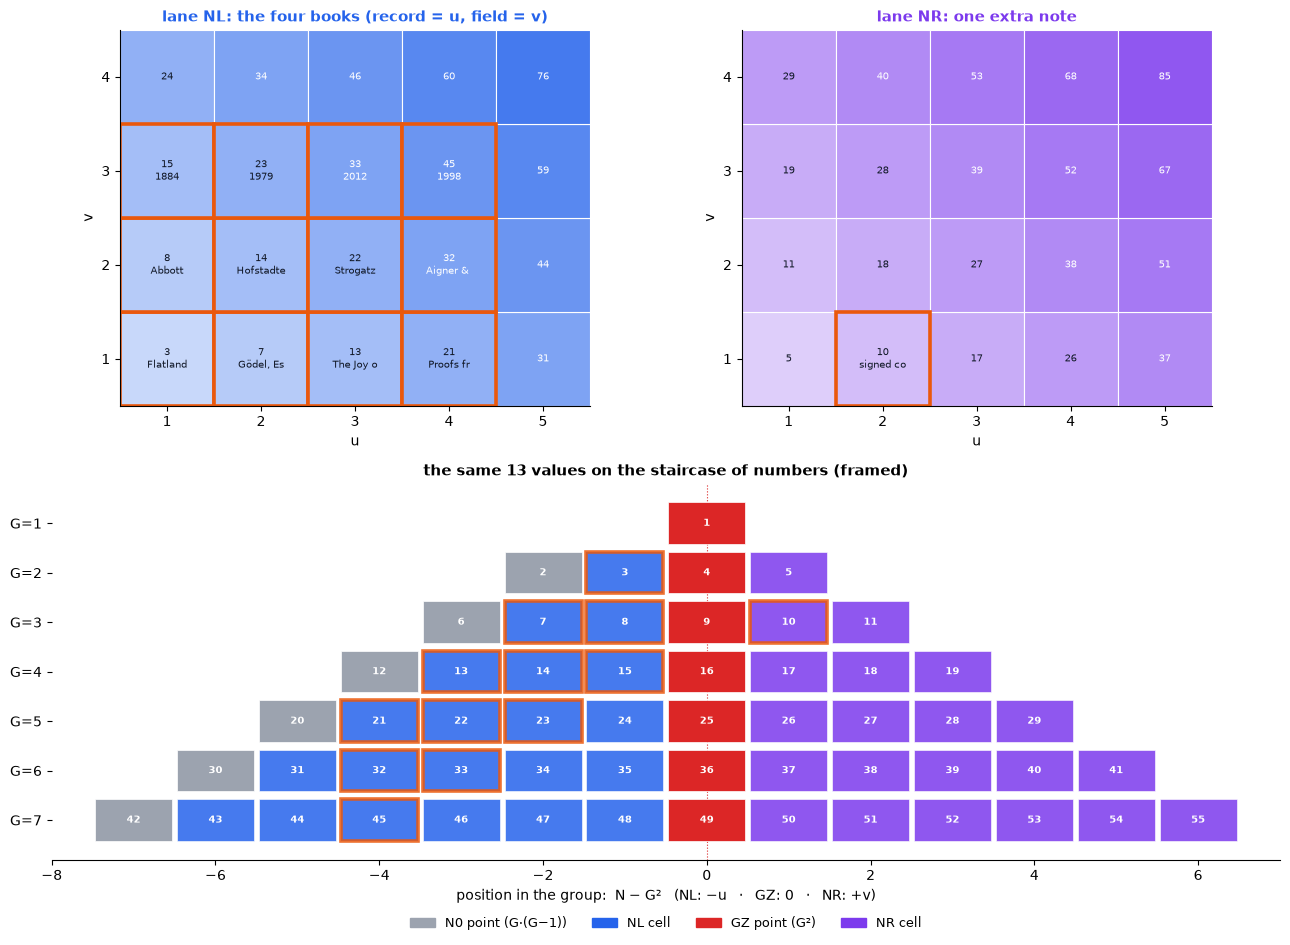

In [4]:
values_nl = {(c["u"], c["v"]): str(c["value"])[:9] for c in cells if c["lane_name"] == "NL"}
values_nr = {(c["u"], c["v"]): str(c["value"])[:9] for c in cells if c["lane_name"] == "NR"}

fig = plt.figure(figsize=(13, 9.5))
ax1 = fig.add_subplot(2, 2, 1)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 1, 2)
plot_address_grid(ax1, 5, 4, "NL", highlight=values_nl, values=values_nl,
                  title="lane NL: the four books (record = u, field = v)")
plot_address_grid(ax2, 5, 4, "NR", highlight=values_nr, values=values_nr,
                  title="lane NR: one extra note")
stored = {int(c["N"][1:]) for c in cells}
plot_staircase(ax3, g_max=7, highlight=stored,
               title="the same 13 values on the staircase of numbers (framed)")
plt.tight_layout()
plt.show()

**Was ist passiert? – ein Datensatz ist eine Zeile von Zellen, keine Reihe von Nachbarn**

* In der Adressebene (oben) ist ein Buch eine einfache **Spalte** `u` mit seinen Feldern bei
  `v = 1, 2, 3`.
* Auf der Treppe (unten) sind dieselben Zellen **über verschiedene Gruppen verteilt**: Der Titel von
  Buch 1 ist `N = 3` (Gruppe 2), sein Autor `N = 8` (Gruppe 3), sein Jahr `N = 15` (Gruppe 4).
* Das spielt überhaupt keine Rolle: Jede Zahl wird in wenigen Rechenschritten aus `(u, v)`
  *berechnet*. Nachbarschaft auf dem Zahlenstrahl ist nicht nötig, um etwas zu finden.
* Die Notiz auf der NR-Lane teilt sich `(u, v) = (2, 1)` mit dem Titel von Buch 2 – trotzdem ist es
  eine andere Zelle mit einer anderen Zahl (`N = 10` statt `N = 7`).

## 3 · Drei Wege zum selben Wert

**Frage:** Wie können wir einen Wert wieder lesen?

Es gibt drei gleichwertige Wege – nimm den, den deine Anwendung kennt:

1. **Über Koordinaten** (Schicht A): Realm, `u`, `v`, Lane.
2. **Über den Datensatz** (Schicht B): Layout und Objektnummer, dann der Feldname.
3. **Über die Zahl** (Schicht A): nur `N`.

▶ **Ausprobieren:** der Autor von Buch 3, dreimal gelesen.

In [5]:
U, V = 3, 2                                  # book 3, field 2 = author
N = nhydb.dynadron_n(1, U, V, "NL")

with nhydb.open(PATH) as db:
    by_coordinates = db.get_value(1, U, V)               # realm, u, v (lane NL is the default)
    by_record = db.get_record(1, U)["author"]            # layout 1, object 3
    by_number = db.get_n(N, mode="cell")                 # only the number

print(f"by coordinates (1, {U}, {V}, NL): {by_coordinates!r}")
print(f"by record      layout 1, object {U}: {by_record!r}")
print(f"by number      N = {N}: {by_number['value']!r}   (field {by_number['field']!r}, record_N {by_number['record_N']})")
assert by_coordinates == by_record == by_number["value"] == "Strogatz"

by coordinates (1, 3, 2, NL): 'Strogatz'
by record      layout 1, object 3: 'Strogatz'
by number      N = 22: 'Strogatz'   (field 'author', record_N N13)


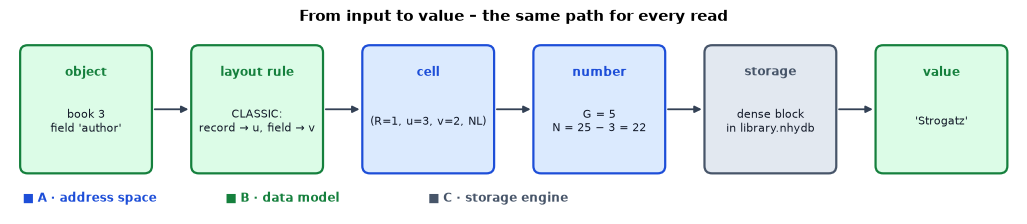

In [6]:
fig, ax = plt.subplots(figsize=(13, 2.4))
plot_path(ax, [
    ("B", "object", "book 3\nfield 'author'"),
    ("B", "layout rule", "CLASSIC:\nrecord → u, field → v"),
    ("A", "cell", f"(R=1, u={U}, v={V}, NL)"),
    ("A", "number", f"G = {U + V}\nN = {(U+V)**2} − {U} = {N}"),
    ("C", "storage", "dense block\nin library.nhydb"),
    ("B", "value", "'Strogatz'"),
], title="From input to value – the same path for every read")
plt.show()

**Was ist passiert?** Alle drei Wege enden in derselben Zelle. Die Farben zeigen die drei Schichten
der Reihe: **grün** ist dein Datenmodell (Bücher, Felder), **blau** der mathematische Adressraum,
**grau** die Speicher-Engine, die die Bytes auf der Platte hält.

### Einen ganzen Datensatz über seine Zahl lesen

Das erste Feld eines Datensatzes (`v = 1`) ist sein **Anker**. Seine Zahl ist die eigene Zahl des
Datensatzes, `record_N`. Wer eine Ankerzahl liest, bekommt den ganzen Datensatz:

In [7]:
anchor_n = nhydb.dynadron_n(1, 3, 1, "NL")
with nhydb.open(PATH) as db:
    rec = db.get_n(anchor_n)                          # mode "auto": anchor → record
    info = db.describe_n(N)                           # what is N = 22?

print(f"N{anchor_n} → {rec['effective_mode']}: {rec['data']}")
print(f"cells of this record: {[c['N'] for c in rec['cells']]}")
print(f"N{N} is {info['interpretation']['kind']} of record {info['interpretation']['record']}, "
      f"field {info['interpretation']['field']!r} in layout {info['layout']['name']!r}")
assert rec["data"]["title"] == "The Joy of x"

N13 → record: {'title': 'The Joy of x', 'author': 'Strogatz', 'year': 2012}
cells of this record: ['N13', 'N22', 'N33']
N22 is record_cell of record 3, field 'author' in layout 'books'


## 4 · Schließen, wieder öffnen, alles ist da

**Frage:** Sind die Daten wirklich dauerhaft gespeichert?

Die `with`-Blöcke oben haben die Datenbank schon mehrmals geschlossen und wieder geöffnet. Hier
die ausdrückliche Prüfung: Vergleiche alles vor und nach einem frischen Öffnen.

In [8]:
with nhydb.open(PATH) as db:
    before = [db.get_record(1, u) for u in range(1, 5)]
    note = db.get_value(1, 2, 1, lane="NR")

# ... the database is closed here; a new process could open it now ...

with nhydb.open(PATH) as db:
    after = [db.get_record(1, u) for u in range(1, 5)]
    assert after == before and db.get_value(1, 2, 1, lane="NR") == note
    print(f"{len(after)} records and the note survived closing and reopening. ✓")
    print(f"recovered_tail_bytes = {db.recovered_tail_bytes} (nothing uncommitted was lost)")

4 records and the note survived closing and reopening. ✓
recovered_tail_bytes = 0 (nothing uncommitted was lost)


## 5 · Ein riesiger Adressraum ist keine riesige Datei

**Frage:** Allein Realm 1 hat `v`-Positionen bis `10^100`. Kostet es Platz, weit entfernt zu schreiben?

▶ **Ausprobieren:** Wir schreiben einen kleinen Wert an immer weiter entfernte Adressen und messen
die Datei nach jedem Commit. Die Adressen wachsen jedes Mal um den Faktor eine Milliarde.

In [9]:
FAR = db_path("far_away.nhydb")
targets = [(1, 1), (10**3, 7), (10**9, 7), (10**30, 7), (7, 10**60), (10**50, 10**99)]

def short(x):
    return str(x) if x < 10**4 else f"10^{len(str(x)) - 1}"


rows = []
with nhydb.create(FAR) as db:
    db.create_realm(1, "far")
    db.commit()
    rows.append({"step": "empty database", "N digits": 0, "file bytes": os.path.getsize(FAR)})
    for u, v in targets:
        db.put_cell(1, u, v, "hello", type="utf8", commit=True)
        n = nhydb.dynadron_n(1, u, v, "NL")
        rows.append({"step": f"u={short(u)}, v={short(v)}",
                     "N digits": len(str(n)), "file bytes": os.path.getsize(FAR)})
    assert all(db.get_value(1, u, v) == "hello" for u, v in targets)

growth = pd.DataFrame(rows)
growth["added bytes"] = growth["file bytes"].diff().fillna(0).astype(int)
growth["bytes for values"] = growth["file bytes"] - growth["file bytes"][0]
growth

,step,N digits,file bytes,added bytes,bytes for values
0,empty database,0,9112,0,0
1,"u=1, v=1",1,9168,56,56
2,"u=1000, v=7",7,9224,56,112
3,"u=10^9, v=7",19,9288,64,176
4,"u=10^30, v=7",61,9368,80,256
5,"u=7, v=10^60",121,9448,80,336
6,"u=10^50, v=10^99",199,9600,152,488


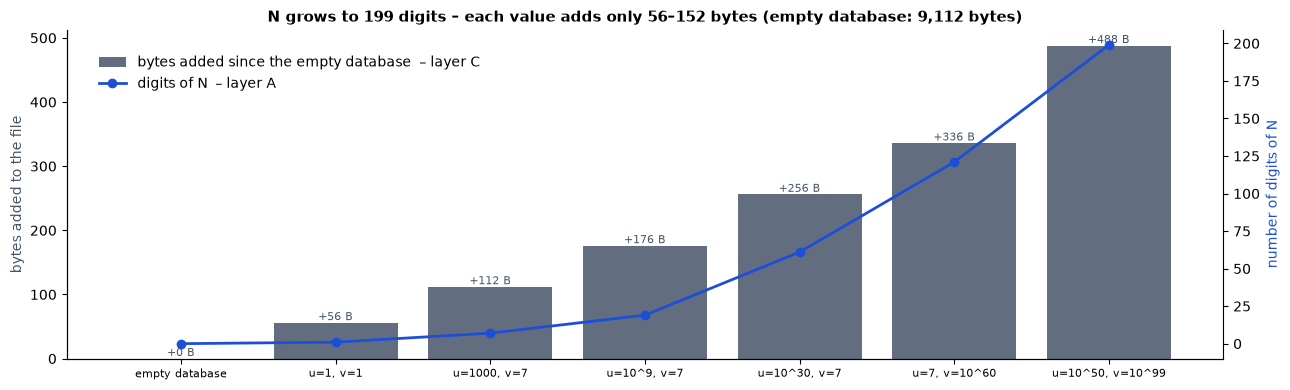

fixed part: two superblocks of 8192 bytes; the rest are small blocks.


In [10]:
fig, ax1 = plt.subplots(figsize=(13, 4))
x = range(len(growth))
ax1.bar(x, growth["bytes for values"], color=COLORS["C"], alpha=0.85,
        label="bytes added since the empty database  – layer C")
for xi, b in zip(x, growth["bytes for values"]):
    ax1.text(xi, b + 4, f"+{b} B", ha="center", fontsize=8, color=COLORS["C"])
ax1.set_ylabel("bytes added to the file", color=COLORS["C"])
ax1.set_xticks(list(x))
ax1.set_xticklabels(growth["step"], fontsize=8)
ax2 = ax1.twinx()
ax2.plot(list(x), growth["N digits"], "o-", color=COLORS["A"], lw=2, label="digits of N  – layer A")
ax2.set_ylabel("number of digits of N", color=COLORS["A"])
ax2.spines["right"].set_visible(True)
added = growth["added bytes"][1:]
ax1.set_title(f"N grows to {growth['N digits'].max()} digits – each value adds only {added.min()}–{added.max()} bytes "
              f"(empty database: {growth['file bytes'][0]:,} bytes)")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88), frameon=False)
plt.tight_layout()
plt.show()

with nhydb.open(FAR) as db:
    storage = db.stats()["storage"]
print("fixed part: two superblocks of", storage["superblocks_bytes"], "bytes; the rest are small blocks.")

**Was ist passiert?** Die Zahl `N` des letzten Werts hat etwa 200 Stellen, und trotzdem kam pro Wert
deutlich weniger als 200 Byte hinzu – ein kleiner Block mit dem Wert und seinen Koordinaten. Sehr
große Koordinaten kosten ein paar Byte mehr, weil die Koordinaten selbst kompakt geschrieben werden
(Ganzzahlen variabler Länge); der leere Raum *zwischen* den Adressen kostet nichts. Den größten Teil
der Datei macht der feste Anfangsteil aus (zwei Superblöcke mit zusammen 8 KiB).
**Ah – Adressen sind kostenlos; nur Werte kosten Platz.**

## 6 · ▶ Deine eigenen Daten

**Ändere es:** Ersetze die Zeilen durch deine eigene Liste (drei Felder: Text, Text, Zahl) und führe
die Zelle aus. Sie baut eine frische Datenbank und zeigt, wo deine Datensätze liegen.

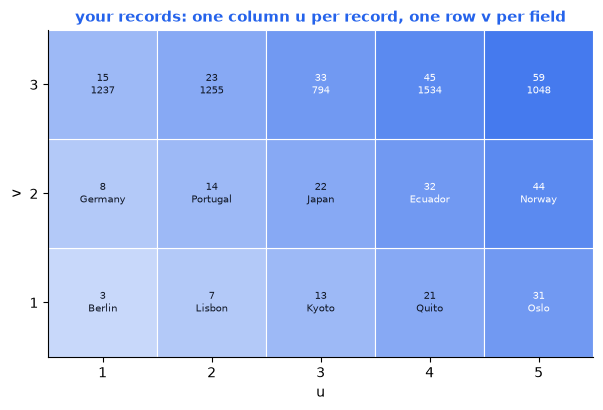

In [11]:
# ▶ Try it: change these values and re-run
MY_ROWS = [
    ["Berlin", "Germany", 1237],
    ["Lisbon", "Portugal", 1255],
    ["Kyoto", "Japan", 794],
    ["Quito", "Ecuador", 1534],
    ["Oslo", "Norway", 1048],
]
FIELDS = [("name", "utf8"), ("country", "utf8"), ("founded", "u16")]

MINE = db_path("mine.nhydb")
with nhydb.create(MINE, overwrite=True) as db:
    db.create_realm(1, "mine")
    db.create_shape(1, 1, "row", [{"v": i + 1, "name": n, "type": t} for i, (n, t) in enumerate(FIELDS)])
    db.create_classic_layout(1, 1, "rows", shape_id=1)
    db.put_dense_batch(1, 1, MY_ROWS, shape_id=1)

with nhydb.open(MINE) as db:
    shown = {(u, v): str(db.get_value(1, u, v))[:9] for u in range(1, len(MY_ROWS) + 1)
             for v in range(1, len(FIELDS) + 1)}
fig, ax = plt.subplots(figsize=(min(13, 2 + 1.6 * len(MY_ROWS)), 4.2))
plot_address_grid(ax, len(MY_ROWS), len(FIELDS), "NL", values=shown,
                  title="your records: one column u per record, one row v per field")
plt.tight_layout()
plt.show()

## 7 · Jetzt du

**Aufgabe:** Lies das `year` von *Proofs from THE BOOK* **nur über seine Zahl `N`**. Bestimme zuerst
die Zelle (welches `u`, welches `v`?), dann die Zahl, dann lies.

In [12]:
# Solution: book 4 → u = 4; year is field 3 → v = 3; lane NL.  G = 7, N = 49 − 4 = 45.
n_year = nhydb.dynadron_n(1, 4, 3, "NL")
with nhydb.open(PATH) as db:
    answer = db.get_n(n_year, mode="cell")
print(f"N = {n_year} → {answer['field']} = {answer['value']}")
assert n_year == 45 and answer["value"] == 1998

N = 45 → year = 1998


## ⏩ Vertiefung: dasselbe auf der Kommandozeile

Das Paket installiert einen Befehl `nhydb` (auch `python -m nhydb`). Er rechnet Adressen und Zahlen
um und liest Zellen – praktisch für schnelle Prüfungen, ohne Python zu schreiben.

In [13]:
import json
import subprocess


def cli(*args):
    out = subprocess.run([sys.executable, "-m", "nhydb", *args, "--json"],
                         capture_output=True, text=True, check=True).stdout
    return json.loads(out)


print("to-n  :", cli("to-n", "--realm", "1", "--u", "3", "--v", "2", "--lane", "NL")["N"])
print("from-n:", {k: cli("from-n", "N45")[k] for k in ("realm", "u", "v_local", "lane_name")})
print("get   :", cli("get", PATH, "u4,v3", "--realm", "1", "--mode", "cell")["value"])

to-n  : 22


from-n:

 {'realm': 1, 'u': 4, 'v_local': 3, 'lane_name': 'NL'}
get   : 1998


## Zusammenfassung

* Ein Realm, eine Shape und ein CLASSIC-Layout genügen: Datensatz = `u`, Feld = `v`.
* Jeder gespeicherte Wert hat eine Zelle und eine Zahl `N`; die Felder eines Datensatzes liegen in verschiedenen Gruppen – und das ist in Ordnung.
* Koordinaten, Datensatz und Zahl sind drei Wege zum selben Wert; Anker (`v = 1`) liefern ganze Datensätze.
* Daten überstehen Schließen und Wiederöffnen; entfernte Adressen kosten keinen Platz – nur Werte.

## Wie es weitergeht

* [03 · Datensätze, Felder und Lanes](03_records_fields_and_lanes_v1.ipynb) – das vollständige Datenmodell.
* [05 · MATH_MAP](05_math_map_text_and_formula_lab_v1.ipynb) – eine Formel entscheidet, wohin die Daten kommen.
* [11 · Was liegt eigentlich auf der Platte?](11_what_lives_on_disk_v1.ipynb) – die Dateien im Detail.

**Cookbook-Abschnitte:** 3 (Deine erste Datenbank), 6 (Datensätze), 10 (Lesen über N), 24 (Kommandozeile) im [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [14]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
